# 05 Time series: trend, seasons, forecasts and volatility

This notebook covers the BUS173 topic on time series. It takes the national monthly price of coarse rice and masur lentils, plus the long-basket Fisher staple index from notebook 01, and works through the usual steps: split each series into trend, seasonal and irregular parts, fit trend lines, test for stationarity, compare three forecasting methods on past data, and then forecast six months ahead. The last section measures which staples swing most from month to month.

Onion was the first choice for the second commodity, but WFP has priced it only since Sep 2024 (about 21 months). That is too short to estimate a seasonal pattern, which needs several years of each calendar month, so lentils take its place in the decomposition. Onion still appears in the volatility section.

The series start in 2007 (palm oil and the index start in May 2007). A few single months are missing in WFP's data. Gaps of up to three months are filled by straight-line interpolation of log prices; the number filled is recorded below. Helper functions are in `src/timeseries.py`. Numbers for the README go to `outputs/tables/key_facts_timeseries.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from plot_utils import *
import timeseries as ts
set_style()
warnings.filterwarnings("ignore")
facts = []
def fact(name, value, how):
    facts.append({"fact": name, "value": value, "how_computed": how})
    print(f"{name}: {value}")
series, filled = {}, {}
for key, kw in {"rice_coarse": dict(item="rice_coarse"), "lentil_masur": dict(item="lentil_masur"),
                "staple_index": dict(index_col="fisher")}.items():
    series[key], filled[key] = ts.monthly_series(**kw)
LABEL = {**ITEM_LABEL, "staple_index": "Staple index (Fisher, 2016 = 100)"}
cov = pd.DataFrame({k: {"start": str(s.index.min().date())[:7], "end": str(s.index.max().date())[:7],
                        "months": len(s), "gaps_filled": filled[k]} for k, s in series.items()}).T
for k in series:
    fact(f"months_{k}", len(series[k]), f"Monthly observations used for {k}, {cov.loc[k,'start']} to {cov.loc[k,'end']}")
    fact(f"gaps_filled_{k}", filled[k], "Missing months filled by log-linear interpolation (max 3 in a row)")
cov

months_rice_coarse: 235
gaps_filled_rice_coarse: 5
months_lentil_masur: 235
gaps_filled_lentil_masur: 3
months_staple_index: 231
gaps_filled_staple_index: 0


,start,end,months,gaps_filled
rice_coarse,2007-01,2026-07,235,5
lentil_masur,2007-01,2026-07,235,3
staple_index,2007-05,2026-07,231,0


## 1. Components: classical decomposition and STL

A monthly price can be thought of as trend x seasonal x irregular. Prices grow in percentage terms, so the multiplicative form fits better than the additive one. Taking logs turns it into an additive sum, which is what STL needs.

- **Classical decomposition** estimates the trend with a centred 2x12 moving average and the seasonal factor as the average ratio of price to trend in each calendar month.
- **STL** (seasonal-trend decomposition using LOESS) does the same job with local regressions, so the seasonal pattern is allowed to change slowly over the years and a few extreme months do not distort it as much (`robust=True`).

stl_seasonal_strength_rice_coarse: 0
stl_trend_strength_rice_coarse: 0.936
stl_seasonal_strength_lentil_masur: 0.021
stl_trend_strength_lentil_masur: 0.931
stl_seasonal_strength_staple_index: 0
stl_trend_strength_staple_index: 0.91


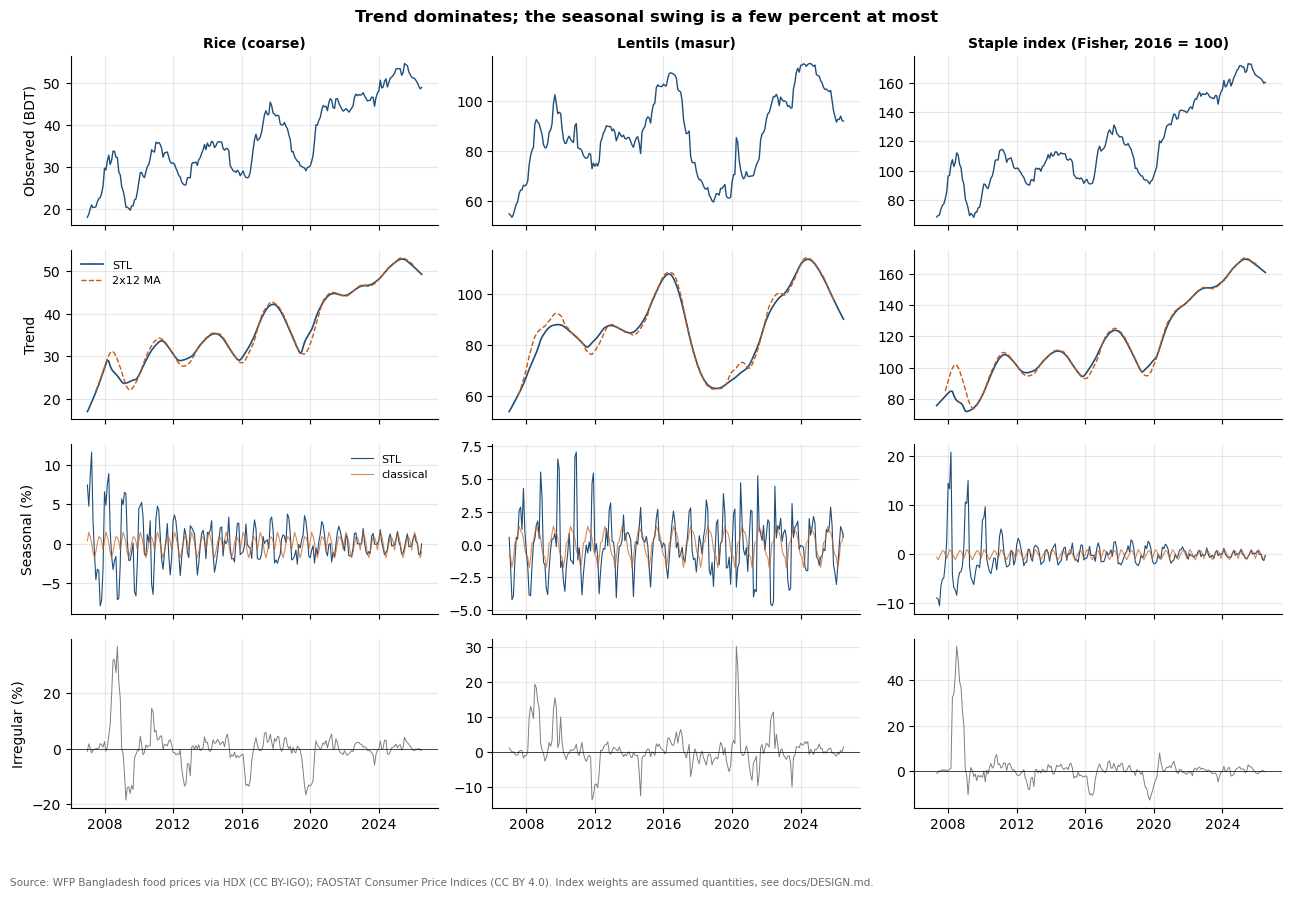

In [2]:
fig, axes = plt.subplots(4, 3, figsize=(13, 9), sharex=True)
for j, (k, s) in enumerate(series.items()):
    stl = STL(np.log(s), period=12, robust=True).fit()
    cl = seasonal_decompose(s, model="multiplicative", period=12)
    axes[0, j].plot(s, color=BLUE, lw=1); axes[0, j].set_title(LABEL[k], fontsize=10)
    axes[1, j].plot(np.exp(stl.trend), color=BLUE, lw=1.2, label="STL")
    axes[1, j].plot(cl.trend, color=ORANGE, lw=1, ls="--", label="2x12 MA")
    axes[2, j].plot(100 * (np.exp(stl.seasonal) - 1), color=BLUE, lw=0.8, label="STL")
    axes[2, j].plot(100 * (cl.seasonal - 1), color=ORANGE, lw=0.8, alpha=0.7, label="classical")
    axes[3, j].plot(100 * (np.exp(stl.resid) - 1), color=GREY, lw=0.7)
    axes[3, j].axhline(0, color="black", lw=0.5)
    fact(f"stl_seasonal_strength_{k}", round(max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var()), 3),
         "STL seasonal strength, 1 - Var(R)/Var(S+R) on log prices (0 = none, 1 = all)")
    fact(f"stl_trend_strength_{k}", round(max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var()), 3),
         "STL trend strength, 1 - Var(R)/Var(T+R) on log prices")
for i, lab in enumerate(["Observed (BDT)", "Trend", "Seasonal (%)", "Irregular (%)"]):
    axes[i, 0].set_ylabel(lab)
axes[1, 0].legend(fontsize=8); axes[2, 0].legend(fontsize=8)
fig.suptitle("Trend dominates; the seasonal swing is a few percent at most", fontweight="bold")
save(fig, "fig30_decomposition", SRC_IDX); plt.show()

The strength measures say how much of the month-to-month movement (after removing the other component) belongs to the trend or to the season. For all three series the trend explains nearly everything and the seasonal part is small. Food prices in Bangladesh moved mostly with general inflation, the 2008 and 2022 world price shocks and the taka depreciation, not with the calendar.

## 2. Seasonal indices by calendar month (ratio-to-moving-average)

The textbook method, step by step:

1. Compute a centred 12-month moving average (a 2x12 MA, so it lines up with the month). This is the trend-cycle.
2. Divide each price by its moving average. The ratio holds the seasonal and irregular parts.
3. Average the ratios for each calendar month over all years.
4. Rescale so that the twelve averages sum to 1,200 (mean 100).

An index of 102 for March means March prices are on average 2% above trend.

seasonal_low_rice_coarse: Jun 98.2
seasonal_high_rice_coarse: Feb 101.4
seasonal_low_lentil_masur: Mar 98.2
seasonal_high_lentil_masur: Aug 101.4
seasonal_low_staple_index: Jun 98.9
seasonal_high_staple_index: Feb 100.9


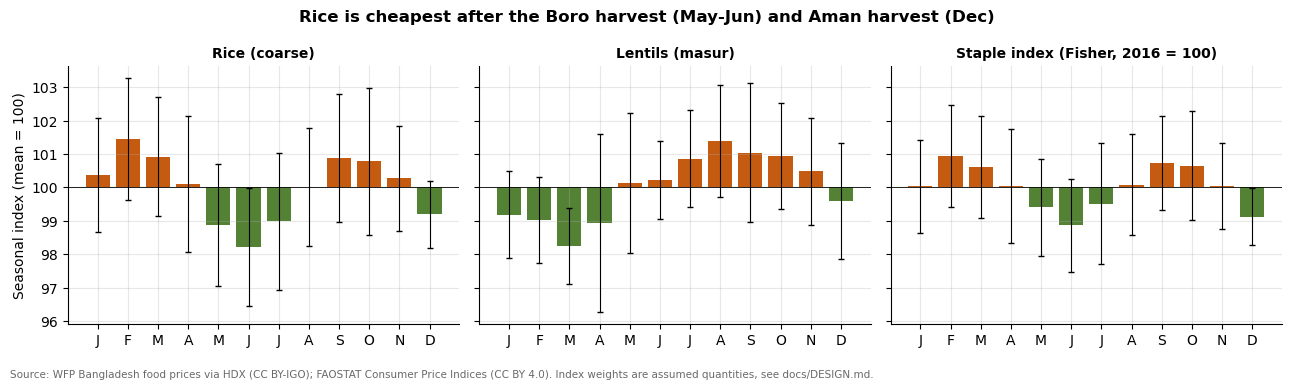

,rice_coarse_seasonal_index,rice_coarse_sd,rice_coarse_n_years,lentil_masur_seasonal_index,lentil_masur_sd,lentil_masur_n_years,staple_index_seasonal_index,staple_index_sd,staple_index_n_years
month,,,,,,,,,
1,100.4,3.8,19,99.2,2.9,19,100.0,3.1,19
2,101.4,4.0,18,99.0,2.8,18,100.9,3.3,18
3,100.9,3.9,18,98.2,2.5,18,100.6,3.3,18
4,100.1,4.4,18,98.9,5.8,18,100.0,3.7,18
5,98.9,3.9,18,100.1,4.5,18,99.4,3.1,18
6,98.2,3.8,18,100.2,2.5,18,98.9,3.0,18
7,99.0,4.6,19,100.9,3.2,19,99.5,3.9,18
8,100.0,3.9,19,101.4,3.7,19,100.1,3.3,18
9,100.9,4.3,19,101.0,4.6,19,100.7,3.1,18


In [3]:
si = {}
for k, s in series.items():
    t, _ = ts.seasonal_index_ratio_ma(s)
    si[k] = t
sitab = pd.concat({k: v for k, v in si.items()}, axis=1)
sitab.columns = [f"{a}_{b}" for a, b in sitab.columns]
sitab.round(2).to_csv(TAB / "ts_seasonal_indices.csv")
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (k, t) in zip(axes, si.items()):
    se = t["sd"] / np.sqrt(t["n_years"])
    ax.bar(range(12), t["seasonal_index"] - 100, bottom=100, color=[GREEN if v < 100 else ORANGE for v in t["seasonal_index"]])
    ax.errorbar(range(12), t["seasonal_index"], yerr=1.96 * se, fmt="none", color="black", lw=0.8, capsize=2)
    ax.axhline(100, color="black", lw=0.6)
    ax.set_xticks(range(12)); ax.set_xticklabels([m[0] for m in months])
    ax.set_title(LABEL[k], fontsize=10)
    lo, hi = t.seasonal_index.idxmin(), t.seasonal_index.idxmax()
    fact(f"seasonal_low_{k}", f"{months[lo-1]} {t.seasonal_index[lo]:.1f}", "Calendar month with lowest ratio-to-MA seasonal index")
    fact(f"seasonal_high_{k}", f"{months[hi-1]} {t.seasonal_index[hi]:.1f}", "Calendar month with highest ratio-to-MA seasonal index")
axes[0].set_ylabel("Seasonal index (mean = 100)")
fig.suptitle("Rice is cheapest after the Boro harvest (May-Jun) and Aman harvest (Dec)", fontweight="bold")
save(fig, "fig31_seasonal_indices", SRC_IDX); plt.show()
sitab.round(1)

Error bars are rough 95% intervals (1.96 x SD / sqrt(years)) for each month's average ratio.

**Rice.** Bangladesh grows three rice crops. Boro (irrigated, dry season) is harvested in April to June and gives more than half the year's output; Aman (monsoon crop) is harvested in November and December; Aus is small. The rice index falls below 100 in May and June, right after Boro arrives, and dips again in December after Aman. It peaks in February to March and September to October, the lean months before each main harvest when stocks run down. The whole range is only about 3 percentage points, so the pattern is real but small compared with year-to-year swings, and the error bars show that several months are not clearly different from 100.

**Lentils.** Masur is a winter (rabi) crop harvested in February and March, and a large share is imported. The index is lowest in March, just after the local harvest, and highest in August. The range is again about 3 points, but STL finds almost no seasonal strength once it lets the pattern drift, so this one should not be leaned on.

**Staple index.** Rice has the largest weight in the index, so the index shows a muted version of the rice pattern.

## 3. Trend: linear and log-linear fits, moving averages, exponential smoothing

A linear trend, price = a + b·t, adds the same number of taka each month. A log-linear trend, ln(price) = a + b·t, adds the same percentage each month, which suits prices better. Both are fitted by OLS with Newey-West (HAC, 12 lags) standard errors, because residuals from a trend line are strongly autocorrelated and ordinary standard errors would make the confidence intervals look too narrow.

trend_growth_pct_yr_rice_coarse: 4.08
trend_growth_pct_yr_lentil_masur: 1.25
trend_growth_pct_yr_staple_index: 3.7


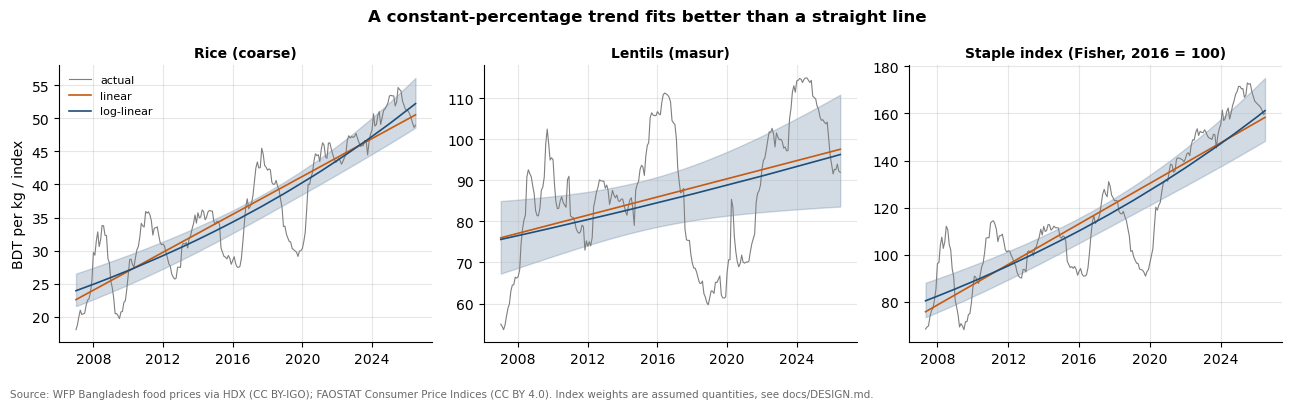

,series,linear_slope_per_month,linear_ci_low,linear_ci_high,linear_r2,loglin_growth_pct_per_year,loglin_ci_low,loglin_ci_high,loglin_r2
0,rice_coarse,0.119,0.099,0.140,0.772,4.076,3.284,4.874,0.743
1,lentil_masur,0.092,0.018,0.167,0.159,1.247,0.144,2.364,0.141
2,staple_index,0.359,0.282,0.436,0.749,3.696,2.907,4.491,0.732


In [4]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (k, s) in zip(axes, series.items()):
    ml, fl = ts.trend_fit(s, log=False)
    mg, fg = ts.trend_fit(s, log=True)
    ax.plot(s, color=GREY, lw=0.8, label="actual")
    ax.plot(fl["mean"], color=ORANGE, lw=1.2, label="linear")
    ax.plot(fg["mean"], color=BLUE, lw=1.2, label="log-linear")
    ax.fill_between(fg.index, fg.mean_ci_lower, fg.mean_ci_upper, color=BLUE, alpha=0.2)
    ax.set_title(LABEL[k], fontsize=10)
    g, (glo, ghi) = mg.params[1], mg.conf_int()[1]
    rows.append({"series": k, "linear_slope_per_month": ml.params[1], "linear_ci_low": ml.conf_int()[1][0],
                 "linear_ci_high": ml.conf_int()[1][1], "linear_r2": ml.rsquared,
                 "loglin_growth_pct_per_year": 100 * (np.exp(12 * g) - 1),
                 "loglin_ci_low": 100 * (np.exp(12 * glo) - 1), "loglin_ci_high": 100 * (np.exp(12 * ghi) - 1),
                 "loglin_r2": mg.rsquared})
    fact(f"trend_growth_pct_yr_{k}", round(rows[-1]["loglin_growth_pct_per_year"], 2),
         f"Log-linear trend growth, % per year, 95% HAC CI {rows[-1]['loglin_ci_low']:.2f} to {rows[-1]['loglin_ci_high']:.2f}")
axes[0].legend(fontsize=8); axes[0].set_ylabel("BDT per kg / index")
fig.suptitle("A constant-percentage trend fits better than a straight line", fontweight="bold")
save(fig, "fig32_trend_fits", SRC_IDX); plt.show()
trend = pd.DataFrame(rows); trend.to_csv(TAB / "ts_trend_fits.csv", index=False); trend.round(3)

The band around the log-linear line is the 95% interval for the trend itself, not for individual months. Prices sit far outside it for years at a time (above it in 2008, 2011 and since 2022), which is another sign that the residuals are autocorrelated and that a single straight line is only a summary, not a model to forecast with.

Moving averages and exponential smoothing follow the series more closely. A trailing 12-month moving average removes the seasonal pattern but lags turning points by about six months. Simple exponential smoothing weights the latest month by alpha and older months by geometrically smaller weights; a small alpha gives a smooth line, a large alpha follows the data. Holt's method adds a smoothed slope.

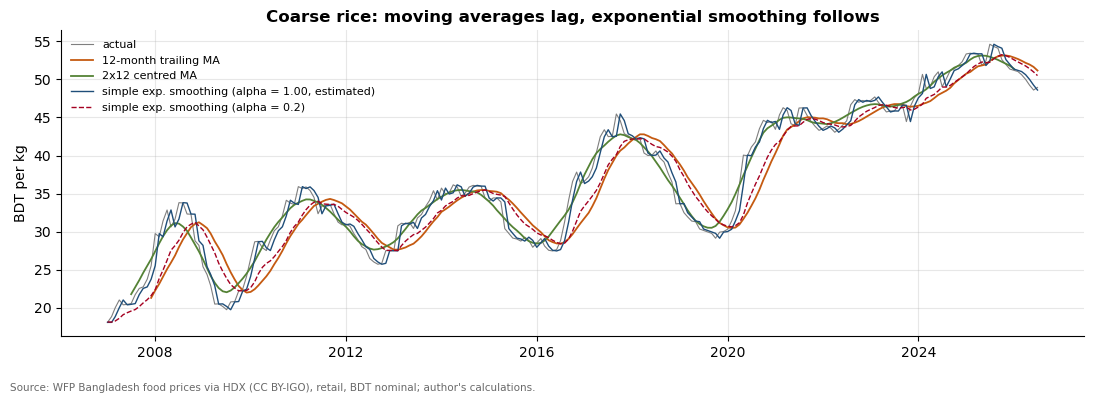

ses_alpha_rice: 1.0


In [5]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
s = series["rice_coarse"]
ses = SimpleExpSmoothing(s, initialization_method="estimated").fit()
holt = Holt(np.log(s), damped_trend=True, initialization_method="estimated").fit()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s, color=GREY, lw=0.8, label="actual")
ax.plot(s.rolling(12).mean(), color=ORANGE, lw=1.3, label="12-month trailing MA")
ax.plot(s.rolling(12, center=True).mean().rolling(2).mean().shift(-1), color=GREEN, lw=1.3, label="2x12 centred MA")
ax.plot(ses.fittedvalues, color=BLUE, lw=1, label=f"simple exp. smoothing (alpha = {ses.params['smoothing_level']:.2f}, estimated)")
ax.plot(SimpleExpSmoothing(s, initialization_method="estimated").fit(smoothing_level=0.2, optimized=False).fittedvalues,
        color=RED, lw=1, ls="--", label="simple exp. smoothing (alpha = 0.2)")
ax.set_ylabel("BDT per kg"); ax.legend(fontsize=8)
ax.set_title("Coarse rice: moving averages lag, exponential smoothing follows")
save(fig, "fig33_smoothing_rice"); plt.show()
fact("ses_alpha_rice", round(ses.params["smoothing_level"], 3), "Estimated alpha of simple exponential smoothing for rice (minimises SSE)")

The estimated alpha for rice is 1, meaning the best one-step guess is almost last month's price. That is what a random walk looks like, and the stationarity tests below agree.

## 4. Stationarity: ADF and KPSS

A series is (weakly) stationary if its mean and variance do not change over time. Most forecasting and regression tools assume it. Two tests with opposite null hypotheses are used together:

- **ADF** (augmented Dickey-Fuller): H0 = the series has a unit root (non-stationary). A small p-value rejects it.
- **KPSS**: H0 = the series is stationary. A small p-value rejects stationarity.

If ADF rejects and KPSS does not, the series is called stationary; the reverse means non-stationary; anything else is mixed. The tests are run on log levels and on the monthly log difference (approximately the % change). KPSS p-values in statsmodels are cut off at 0.01 and 0.10, so values at those bounds mean "at most" or "at least".

In [6]:
rows = []
for k, s in series.items():
    rows.append(ts.stationarity(np.log(s), f"{k}: log level"))
    rows.append(ts.stationarity(np.log(s).diff(), f"{k}: monthly log change"))
cpi = pd.read_parquet(PROC / "indices_long.parquet").set_index("date").cpi_food_2016.dropna()
cpi = cpi[cpi.index >= "2007-01-01"]
rows.append(ts.stationarity(np.log(cpi), "food CPI: log level"))
rows.append(ts.stationarity(np.log(cpi).diff(), "food CPI: monthly log change"))
st = pd.DataFrame(rows); st.to_csv(TAB / "ts_stationarity.csv", index=False)
for r in rows:
    fact("stationarity_" + r["series"].replace(": ", "_").replace(" ", "_"), r["verdict"],
         f"ADF p = {r['adf_p']:.3f}, KPSS p = {r['kpss_p']:.3f}")
st.round(3)

stationarity_rice_coarse_log_level: non-stationary
stationarity_rice_coarse_monthly_log_change: stationary
stationarity_lentil_masur_log_level: stationary
stationarity_lentil_masur_monthly_log_change: stationary
stationarity_staple_index_log_level: non-stationary
stationarity_staple_index_monthly_log_change: stationary
stationarity_food_CPI_log_level: non-stationary
stationarity_food_CPI_monthly_log_change: stationary


,series,n,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
0,rice_coarse: log level,235,-2.243,0.191,3,1.935,0.010,non-stationary
1,rice_coarse: monthly log change,234,-6.021,0.000,2,0.063,0.100,stationary
2,lentil_masur: log level,235,-2.868,0.049,3,0.421,0.068,stationary
3,lentil_masur: monthly log change,234,-6.648,0.000,2,0.149,0.100,stationary
4,staple_index: log level,231,-2.096,0.246,3,1.864,0.010,non-stationary
5,staple_index: monthly log change,230,-5.439,0.000,2,0.040,0.100,stationary
6,food CPI: log level,234,0.520,0.985,12,2.201,0.010,non-stationary
7,food CPI: monthly log change,233,-3.006,0.034,11,0.042,0.100,stationary


Log levels of rice, the staple index and the food CPI are non-stationary: ADF cannot reject a unit root and KPSS rejects stationarity. Lentils sit on the line. ADF just rejects (p = 0.049) and KPSS just fails to reject at 5% (p = 0.07), so the rule labels the lentil log level stationary. With both p-values this close to the cut-off, and a price that has wandered for 20 years, lentils are treated like the others and differenced once. Monthly log changes are stationary on both tests for all four series. The practical conclusion for modelling is one difference (d = 1), which is what the SARIMA model below uses.

The ACF and PACF of the monthly change in log rice prices show how much this month's change carries into the next.

acf1_dlog_rice_coarse: 0.34
acf1_dlog_staple_index: 0.376


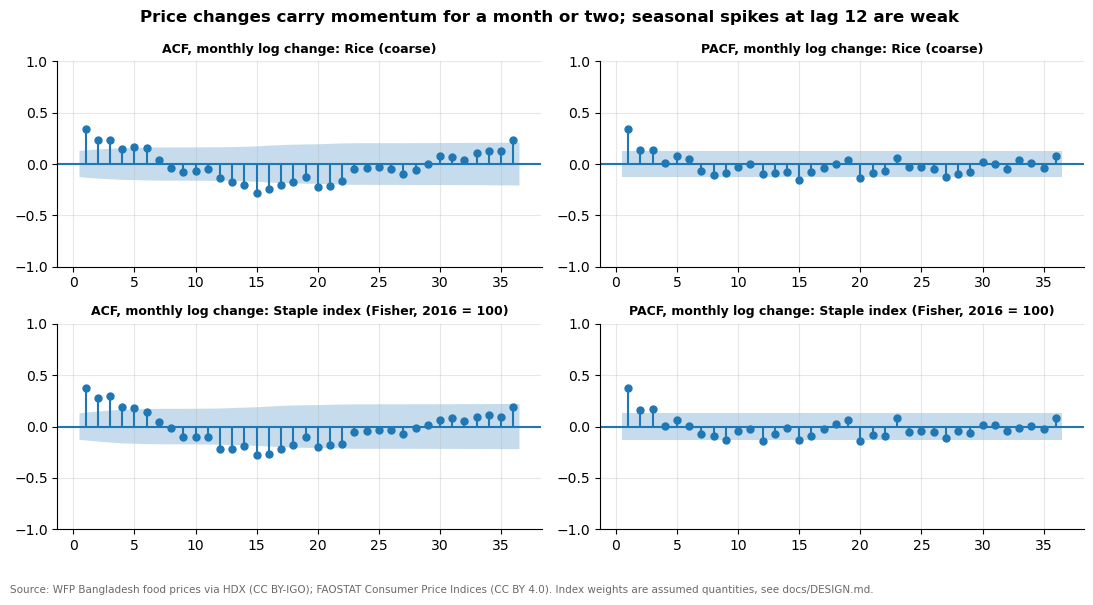

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for i, k in enumerate(["rice_coarse", "staple_index"]):
    d = np.log(series[k]).diff().dropna()
    plot_acf(d, lags=36, ax=axes[i, 0], zero=False, title=f"ACF, monthly log change: {LABEL[k]}")
    plot_pacf(d, lags=36, ax=axes[i, 1], zero=False, method="ywm", title=f"PACF, monthly log change: {LABEL[k]}")
    from statsmodels.tsa.stattools import acf
    fact(f"acf1_dlog_{k}", round(acf(d, nlags=1)[1], 3), "Lag-1 autocorrelation of monthly log change")
for ax in axes.flat:
    ax.title.set_fontsize(9)
fig.suptitle("Price changes carry momentum for a month or two; seasonal spikes at lag 12 are weak", fontweight="bold")
save(fig, "fig34_acf_pacf", SRC_IDX); plt.show()

The first one or two autocorrelations are positive and outside the bands: a price rise this month makes a rise next month more likely. The PACF cuts off after lag 1 or 2, which suggests a low-order AR term. Spikes at lag 12 are small, matching the weak seasonality found above.

## 5. Forecasting and backtest

Three methods, all fitted to log prices (so forecasts are in percentage terms) except the naive one:

- **Seasonal naive**: next March equals last March. A baseline that any serious method should beat.
- **ETS**: Holt-Winters exponential smoothing with a damped additive trend and additive seasonality on logs.
- **SARIMA(1,1,1)(0,0,1)12 with drift**: one difference (from the stationarity tests), AR(1) and MA(1) for the short-run momentum in the ACF/PACF, and a seasonal MA term for the weak lag-12 pattern.

**Rolling-origin backtest.** Pretend it is an earlier month (the origin), fit each method on data up to then, forecast the next 12 months, and compare with what actually happened. Origins every three months from Jul 2022 to Jul 2025 give 13 origins; the later ones have fewer than 12 months to check. Accuracy measures:

- **MAPE**: mean absolute % error.
- **MASE**: mean absolute error divided by the in-sample mean absolute error of a seasonal naive forecast. Below 1 means better than the naive method did within the training data.

**Rule for picking the model**: the method with the lowest average MASE over horizons 1 to 6 across all origins is used for the 6-month forecast. MASE is chosen over MAPE because it does not depend on the price level.

In [8]:
origins = pd.date_range("2022-07-01", "2025-07-01", freq="3MS")
bt = pd.concat({k: ts.backtest(series[k], origins, h=12) for k in ["rice_coarse", "staple_index"]}, names=["series"]).reset_index(0).reset_index(drop=True)
bt.to_csv(TAB / "ts_backtest_errors.csv", index=False)
bt["h_band"] = np.where(bt.horizon <= 6, "h1-6", "h7-12")
summ = bt.groupby(["series", "method", "h_band"]).agg(MAPE=("ape", "mean"), MASE=("ase", "mean"), n=("ape", "size")).unstack("h_band")
summ.columns = [f"{a}_{b}" for a, b in summ.columns]
summ = summ.reset_index(); summ.to_csv(TAB / "ts_backtest_summary.csv", index=False)
best = summ.loc[summ.groupby("series")["MASE_h1-6"].idxmin(), ["series", "method"]].set_index("series").method
for k in best.index:
    r = summ[(summ.series == k) & (summ.method == best[k])].iloc[0]
    fact(f"best_method_{k}", best[k], "Lowest mean MASE at horizons 1-6 over 13 rolling origins (Jul 2022 - Jul 2025)")
    fact(f"best_mape_h1_6_{k}", round(r["MAPE_h1-6"], 2), "MAPE (%) of chosen method, horizons 1-6")
    fact(f"best_mase_h1_6_{k}", round(r["MASE_h1-6"], 3), "MASE of chosen method, horizons 1-6")
summ.round(3)

best_method_rice_coarse: sarima
best_mape_h1_6_rice_coarse: 3.55
best_mase_h1_6_rice_coarse: 0.288
best_method_staple_index: ets
best_mape_h1_6_staple_index: 2.85
best_mase_h1_6_staple_index: 0.284


,series,method,MAPE_h1-6,MAPE_h7-12,MASE_h1-6,MASE_h7-12,n_h1-6,n_h7-12
0,rice_coarse,ets,3.585,6.666,0.293,0.554,78,78
1,rice_coarse,sarima,3.546,6.742,0.288,0.555,78,78
2,rice_coarse,seasonal_naive,5.900,5.716,0.482,0.472,78,78
3,staple_index,ets,2.848,5.658,0.284,0.570,78,78
4,staple_index,sarima,2.864,5.955,0.286,0.602,78,78
5,staple_index,seasonal_naive,5.348,4.895,0.534,0.497,78,78


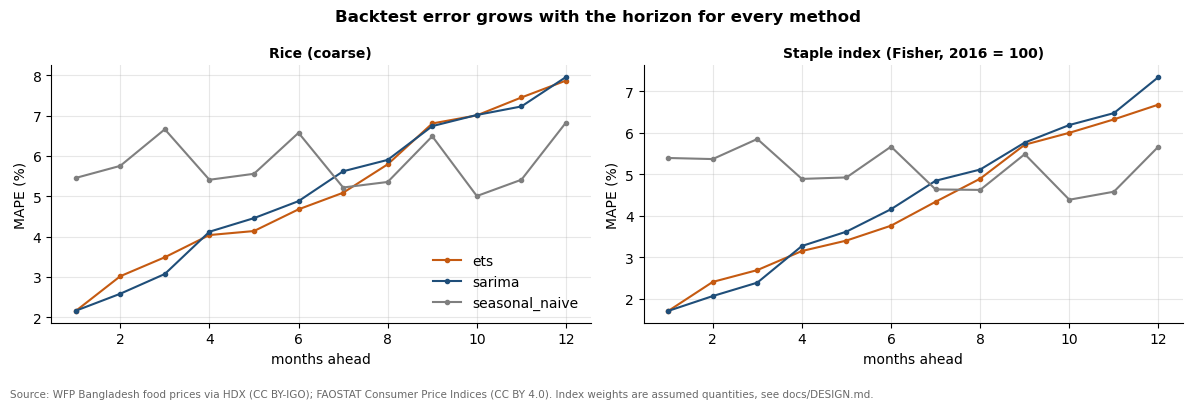

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cols = {"seasonal_naive": GREY, "ets": ORANGE, "sarima": BLUE}
for ax, k in zip(axes, ["rice_coarse", "staple_index"]):
    g = bt[bt.series == k].groupby(["method", "horizon"]).ape.mean().unstack(0)
    for m in g:
        ax.plot(g.index, g[m], marker="o", ms=3, color=cols[m], label=m)
    ax.set_xlabel("months ahead"); ax.set_ylabel("MAPE (%)"); ax.set_title(LABEL[k], fontsize=10)
axes[0].legend()
fig.suptitle("Backtest error grows with the horizon for every method", fontweight="bold")
save(fig, "fig35_backtest_mape", SRC_IDX); plt.show()

## 6. Six-month forecast

The chosen method is refitted on all data and run six months past the last observation. Intervals:

- SARIMA: the model's own 80% and 95% prediction intervals.
- ETS: 2,000 simulated future paths with resampled errors; the 10th/90th and 2.5th/97.5th percentiles.
- Seasonal naive: last year's same month, with a band from the standard deviation of past 12-month log changes.

All intervals are computed for log prices and then converted back, so they are wider above the line than below.

forecast_rice_coarse_2027-01: 48.5
forecast_staple_index_2027-01: 160.9


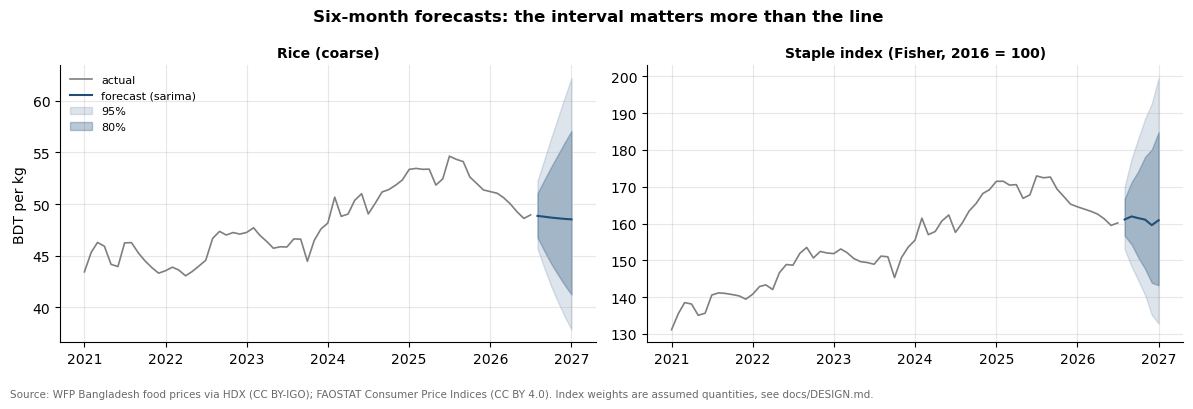

,series,date,method,forecast,lo80,hi80,lo95,hi95,last_actual_month,last_actual
0,rice_coarse,2026-08-01,sarima,48.85,46.76,51.04,45.69,52.23,2026-07-01,48.95
1,rice_coarse,2026-09-01,sarima,48.77,45.45,52.34,43.78,54.33,2026-07-01,48.95
2,rice_coarse,2026-10-01,sarima,48.69,44.26,53.56,42.08,56.34,2026-07-01,48.95
3,rice_coarse,2026-11-01,sarima,48.62,43.17,54.77,40.53,58.33,2026-07-01,48.95
4,rice_coarse,2026-12-01,sarima,48.56,42.16,55.94,39.13,60.28,2026-07-01,48.95
5,rice_coarse,2027-01-01,sarima,48.52,41.24,57.08,37.84,62.20,2026-07-01,48.95
6,staple_index,2026-08-01,ets,161.09,156.67,166.71,152.98,169.97,2026-07-01,160.16
7,staple_index,2026-09-01,ets,161.93,154.32,171.21,148.32,177.53,2026-07-01,160.16
8,staple_index,2026-10-01,ets,161.47,150.81,174.19,144.58,183.07,2026-07-01,160.16
9,staple_index,2026-11-01,ets,161.05,147.65,178.13,140.53,188.49,2026-07-01,160.16


In [10]:
from scipy import stats
out = []
for k in ["rice_coarse", "staple_index"]:
    s, m = series[k], best[k]
    idx = pd.date_range(s.index[-1] + pd.offsets.MonthBegin(), periods=6, freq="MS")
    if m == "sarima":
        _, res = ts.fc_sarima(s, 6, return_model=True)
        f = res.get_forecast(6); mean = f.predicted_mean.values
        q = {a: f.conf_int(alpha=a).values for a in (0.05, 0.2)}
        lo95, hi95, lo80, hi80 = q[0.05][:, 0], q[0.05][:, 1], q[0.2][:, 0], q[0.2][:, 1]
    elif m == "ets":
        _, res = ts.fc_ets(s, 6, return_model=True)
        # statsmodels ignores random_state when random_errors="bootstrap", so draw the resampled errors here
        rng = np.random.default_rng(20261024)
        eps = rng.choice(np.asarray(res.resid), size=(6, 2000), replace=True)
        sims = res.simulate(6, repetitions=2000, error="add", random_errors=eps).values
        mean = res.forecast(6).values
        lo95, hi95, lo80, hi80 = [np.percentile(sims, p, axis=1) for p in (2.5, 97.5, 10, 90)]
    else:
        mean = np.log(ts.fc_snaive(s, 6)); sd = np.log(s).diff(12).std()
        lo95, hi95, lo80, hi80 = mean - 1.96 * sd, mean + 1.96 * sd, mean - 1.28 * sd, mean + 1.28 * sd
    for i, d in enumerate(idx):
        out.append({"series": k, "date": d, "method": m, "forecast": np.exp(mean[i]), "lo80": np.exp(lo80[i]),
                    "hi80": np.exp(hi80[i]), "lo95": np.exp(lo95[i]), "hi95": np.exp(hi95[i]),
                    "last_actual_month": s.index[-1], "last_actual": s.iloc[-1]})
fc = pd.DataFrame(out)
fc.to_csv(PROC / "forecast_6m.csv", index=False); fc.to_csv(TAB / "ts_forecast_6m.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, ["rice_coarse", "staple_index"]):
    s, f = series[k], fc[fc.series == k]
    ax.plot(s[s.index >= "2021-01-01"], color=GREY, lw=1.2, label="actual")
    ax.plot(f.date, f.forecast, color=BLUE, lw=1.5, label=f"forecast ({best[k]})")
    ax.fill_between(f.date, f.lo95, f.hi95, color=BLUE, alpha=0.15, label="95%")
    ax.fill_between(f.date, f.lo80, f.hi80, color=BLUE, alpha=0.3, label="80%")
    ax.set_title(LABEL[k], fontsize=10)
    last = f.iloc[-1]
    fact(f"forecast_{k}_{str(last.date.date())[:7]}", round(last.forecast, 1),
         f"{best[k]} forecast, 95% interval {last.lo95:.1f} to {last.hi95:.1f}; last actual {f.last_actual.iloc[0]:.1f} in {str(f.last_actual_month.iloc[0].date())[:7]}")
axes[0].set_ylabel("BDT per kg"); axes[0].legend(fontsize=8)
fig.suptitle("Six-month forecasts: the interval matters more than the line", fontweight="bold")
save(fig, "fig36_forecast_6m", SRC_IDX); plt.show()
fc.round(2)

At horizons 1 to 6, SARIMA won for rice and ETS won for the staple index. In both cases the other model was a close second, and MAPE was about 3 to 4%. Beyond six months the seasonal naive method did best, because both models extend recent momentum too far. That is one reason to stop at six months. Read the forecast with the backtest in mind: the typical error within six months was 3 to 4%, and errors were larger when prices were turning. The intervals show the range the model expects if the next six months look like the past; a new policy change, flood or exchange-rate jump would push prices outside them.

## 7. Volatility: which staple swings most?

Volatility here is the standard deviation of monthly log changes (roughly, the typical month-on-month % change), computed over rolling 12-month windows. For the four long-basket items this gives a history back to 2008. The seven items added in Sep 2024 have only about 20 monthly changes, so for them one SD over the whole short window is reported, and all eleven items are compared on that same window.

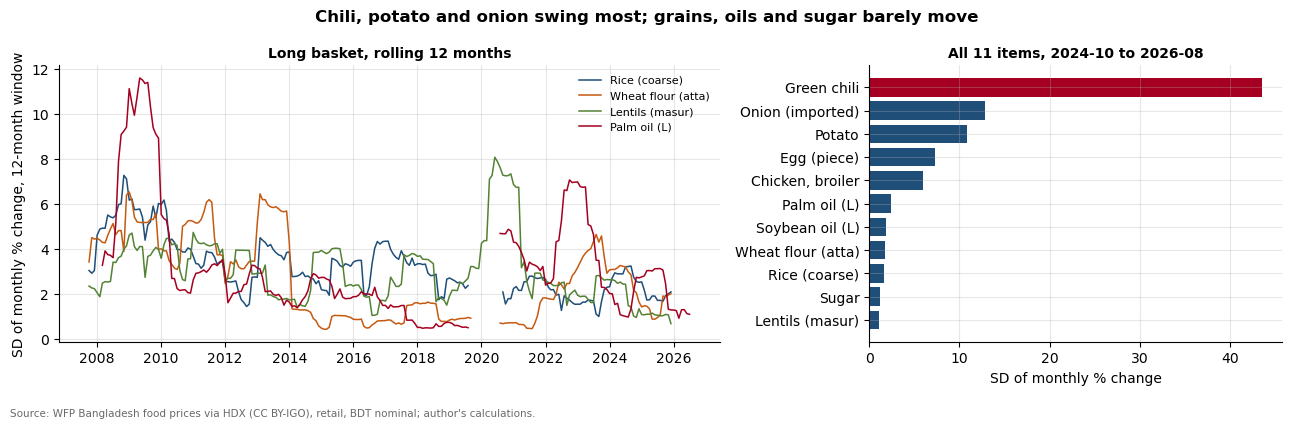

most_volatile_item_short: chili_green
most_volatile_sd_pct: 43.6
onion_sd_mm_pct: 12.8
rice_sd_mm_pct_short: 1.7
most_volatile_long_basket: palm_oil
peak_rolling_vol: palm_oil 2009-05 11.6


,sd_mm_pct_short_window,n_changes_short,mean_abs_mm_pct_short,sd_mm_pct_2007_2026,max_rise_pct_short,max_fall_pct_short
item,,,,,,
chili_green,43.55,18,30.90,NaN,109.35,-72.27
onion,12.78,16,8.43,NaN,11.52,-35.47
potato,10.88,11,7.34,NaN,17.31,-23.97
egg,7.31,18,5.78,NaN,15.27,-9.32
chicken_broiler,5.96,18,5.00,NaN,9.69,-9.75
palm_oil,2.44,20,1.64,4.16,7.34,-2.43
soybean_oil,1.89,18,1.56,NaN,4.87,-3.33
atta,1.71,19,1.26,3.51,5.14,-1.84
rice_coarse,1.67,18,1.23,3.66,4.10,-2.93


In [11]:
nat = pd.read_parquet(PROC / "national_prices.parquet")
wide = nat.pivot(index="date", columns="item", values="price_bdt").asfreq("MS")
dl = 100 * np.log(wide).diff()
long_items = ["rice_coarse", "atta", "lentil_masur", "palm_oil"]
roll = dl[long_items][dl.index >= "2007-01-01"].rolling(12, min_periods=10).std()
roll.to_csv(TAB / "ts_rolling_volatility.csv")
short = dl[dl.index >= "2024-10-01"]
vol = pd.DataFrame({"sd_mm_pct_short_window": short.std(), "n_changes_short": short.count(),
                    "mean_abs_mm_pct_short": short.abs().mean(),
                    "sd_mm_pct_2007_2026": dl[dl.index >= "2007-01-01"].std().where(lambda x: x.index.isin(long_items)),
                    "max_rise_pct_short": short.max(), "max_fall_pct_short": short.min()}).sort_values("sd_mm_pct_short_window", ascending=False)
vol.index.name = "item"; vol.to_csv(TAB / "ts_volatility.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for c, col in zip(long_items, [BLUE, ORANGE, GREEN, RED]):
    axes[0].plot(roll[c], color=col, lw=1.1, label=ITEM_LABEL[c])
axes[0].set_ylabel("SD of monthly % change, 12-month window"); axes[0].legend(fontsize=8)
axes[0].set_title("Long basket, rolling 12 months", fontsize=10)
v = vol.sd_mm_pct_short_window.sort_values()
axes[1].barh([ITEM_LABEL[i] for i in v.index], v.values, color=[RED if i == v.idxmax() else BLUE for i in v.index])
axes[1].set_xlabel("SD of monthly % change"); axes[1].set_title(f"All 11 items, {str(short.index.min().date())[:7]} to {str(short.dropna(how='all').index.max().date())[:7]}", fontsize=10)
fig.suptitle("Chili, potato and onion swing most; grains, oils and sugar barely move", fontweight="bold")
save(fig, "fig37_volatility"); plt.show()
fact("most_volatile_item_short", vol.index[0], "Highest SD of monthly log change since Oct 2024 (national mean)")
fact("most_volatile_sd_pct", round(vol.iloc[0].sd_mm_pct_short_window, 1), "SD of monthly % change of the most volatile item since Oct 2024")
fact("onion_sd_mm_pct", round(vol.loc["onion"].sd_mm_pct_short_window, 1), "SD of monthly % change, imported onion, since Oct 2024")
fact("rice_sd_mm_pct_short", round(vol.loc["rice_coarse"].sd_mm_pct_short_window, 1), "SD of monthly % change, coarse rice, since Oct 2024")
lv = vol.sd_mm_pct_2007_2026.dropna().sort_values(ascending=False)
fact("most_volatile_long_basket", lv.index[0], f"Highest SD of monthly log change 2007-2026 among long-basket items ({lv.iloc[0]:.1f}%)")
pk = roll.stack().idxmax()
fact("peak_rolling_vol", f"{pk[1]} {str(pk[0].date())[:7]} {roll.stack().max():.1f}", "Highest rolling 12-month SD of monthly % change, long basket")
vol.round(2)

Green chili is by far the most volatile item, followed by potato and then onion. All three are perishable or semi-perishable, and their supply depends on one harvest or on imports. Onion, the item expected to top the list, comes third. Eggs and chicken sit in the middle. Rice, wheat flour, the two oils, sugar and lentils all have a monthly SD under 2.5%. Over 2007 to 2026 palm oil is the most volatile of the long-basket items, following world vegetable oil prices and the exchange rate; its rolling volatility peaked in the window ending May 2009, after the 2008 world price spike.

## Key facts

In [12]:
kf = pd.DataFrame(facts); kf.to_csv(TAB / "key_facts_timeseries.csv", index=False); kf

,fact,value,how_computed
0,months_rice_coarse,235,"Monthly observations used for rice_coarse, 200..."
1,gaps_filled_rice_coarse,5,Missing months filled by log-linear interpolat...
2,months_lentil_masur,235,"Monthly observations used for lentil_masur, 20..."
3,gaps_filled_lentil_masur,3,Missing months filled by log-linear interpolat...
4,months_staple_index,231,"Monthly observations used for staple_index, 20..."
5,gaps_filled_staple_index,0,Missing months filled by log-linear interpolat...
6,stl_seasonal_strength_rice_coarse,0,"STL seasonal strength, 1 - Var(R)/Var(S+R) on ..."
7,stl_trend_strength_rice_coarse,0.936,"STL trend strength, 1 - Var(R)/Var(T+R) on log..."
8,stl_seasonal_strength_lentil_masur,0.021,"STL seasonal strength, 1 - Var(R)/Var(S+R) on ..."
9,stl_trend_strength_lentil_masur,0.931,"STL trend strength, 1 - Var(R)/Var(T+R) on log..."


## Limits

- National prices are a matched-sample chain of division medians (notebook 01): before 2020 that means six division series, after 2020 district markets. The 2020 design change may add a level shift that a decomposition reads as trend.
- Gap filling interpolates between the months on either side of a gap, so a filled month uses the observation after it. For the backtest this is a mild look-ahead. It affects only 3 to 5 months per series.
- The SARIMA order and the ETS form were chosen after looking at the full-sample ACF and PACF plots in section 4. The backtest itself only fits each model on data before each origin, but the model forms were not chosen blind.
- Seasonal indices assume a fixed pattern over 19 years. STL lets it drift, and the two agree closely, but neither can say much about items with two years of data.
- The backtest origins (2022 to 2025) include the post-2022 inflation surge, which is the hard part of the sample. Results on a calmer period would look better for all methods.
- The forecast is univariate. It knows nothing about world prices, the exchange rate or harvest news. Notebook 04 looks at those links.